In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import pandas as pd
from src.cleaning import load_processed
from src.metrics import add_core_metrics, add_growth_rate, add_cumulative_net_intake

df = add_cumulative_net_intake(add_growth_rate(add_core_metrics(load_processed())))
rep = df[df["is_reported"]]
print(df[["load_growth_pct", "cumulative_net_intake"]].isna().sum())   # 356 and 355


load_growth_pct          356
cumulative_net_intake    355
dtype: int64


In [2]:
print(rep["load_growth_pct"].describe().round(2))
print("rose:", (rep["load_growth_pct"] > 0).sum(),
      " fell:", (rep["load_growth_pct"] < 0).sum(),
      " same:", (rep["load_growth_pct"] == 0).sum())
print("fastest rise:", rep["load_growth_pct_per_day"].idxmax().date())
print("fastest fall:", rep["load_growth_pct_per_day"].idxmin().date())

count    719.0
mean     -0.12
std        1.9
min      -11.6
25%      -0.69
50%       0.12
75%       0.86
max       8.34
Name: load_growth_pct, dtype: Float64
rose: 387  fell: 326  same: 6
fastest rise: 2023-07-18
fastest fall: 2025-02-02


In [3]:
rep.groupby(rep.index.year)["load_growth_pct_per_day"].agg(["mean", "std"]).round(3)

,mean,std
date,,
2023,0.534,1.365
2024,0.159,1.085
2025,-0.218,0.843


<Axes: title={'center': 'Cumulative net intake vs actual HHS change'}, xlabel='date'>

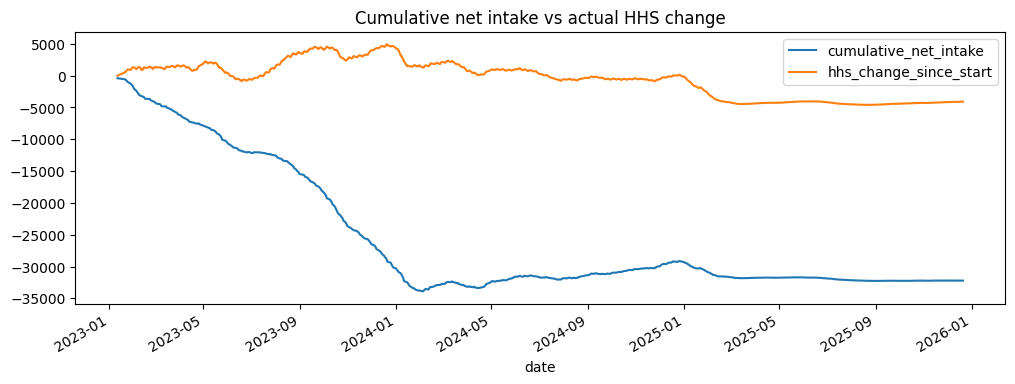

In [4]:
rep[["cumulative_net_intake", "hhs_change_since_start"]].astype(float).plot(
    figsize=(12, 4), title="Cumulative net intake vs actual HHS change")

In [5]:
(rep[["cumulative_net_intake", "hhs_change_since_start", "unexplained_change"]]
    .groupby(rep.index.to_period("Q")).last())

,cumulative_net_intake,hhs_change_since_start,unexplained_change
date,,,
2023Q1,-6102,1592,7694
2023Q2,-12050,-508,11542
2023Q3,-18018,4418,22436
2023Q4,-30120,4664,34784
2024Q1,-33176,691,33867
2024Q2,-31643,308,31951
2024Q3,-31095,-599,30496
2024Q4,-29257,-112,29145
2025Q1,-31775,-4373,27402
